# NMF 空间权重 · 分组件高斯表面密度

本 notebook 为每个 NMF 空间权重（`loading_sensory` / `loading_sustain` / `loading_motor`）各画一张高斯平滑的岛叶表面密度图；**不**做三色 RGB 混合。表面与 Figure 2 的 B 层岛叶图一致：`cvs_avg35_inMNI152` 的 FreeSurfer **pial**，再叠 `aparc.a2009s` 岛叶标签网格（见 `vizpub/fig2.ipynb` 的 `insula_mesh` / `make_insula_brains`，`surf="pial"`）。

请在 **compute node**（`ieeg` 环境）运行：本 notebook 含 PyVista / MNE 渲染，勿在 DCC login 节点执行。

In [36]:
# --- Parameters (edit these) ---
DENSITY_BANDWIDTH = 5.0       # mm; Gaussian kernel σ (same as fig2 / functional_hga)
DENSITY_MAX_DISTANCE = 6.0    # mm; zero density beyond nearest electrode
DENSITY_VISIBLE_FRACTION = 0.10  # fraction of each component × hemisphere peak; larger = smaller, more selective visible area
DENSITY_COLOR_VMAX_PERCENTILE = 99.0  # robust upper limit for the visible alpha gradient
COMPONENTS = ("sensory", "sustain", "motor")  # one SVG per component
EXCLUDE_SUBJECTS = {"D0121"}  # same as fig2

# 2D screenshot-space envelope uses only the already-thresholded visible overlay.
# This small floor rejects screenshot compositing noise; it is not another density cutoff.
ENVELOPE_MIN_COLOR_SIGNAL = 0.03  # draw none when a hemisphere has negligible visible density
ENVELOPE_CLOSE_RADIUS_PX = 18
ENVELOPE_MIN_AREA_PX = 120
ENVELOPE_SMOOTH_SIGMA_PX = 7.0
ENVELOPE_LINE_WIDTH_PX = 1.4
ENVELOPE_COLOR = "#222222"


In [37]:
import os
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
import pandas as pd
from matplotlib.patches import Patch
from scipy.spatial import cKDTree
from scipy.spatial.distance import cdist

ROOT = Path("..").resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.nmf.waveform_analysis import CLUSTER_LABELS, FUNCTION_COLORS
from src.paths import img_dir, nmf_assignments_path, save_svg

cm = 1 / 2.54
plt.rcParams["svg.fonttype"] = "none"
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Arial"]
fontsize = 7

IMG_DIR = img_dir("nmf")
NMF_ASSIGNMENTS = nmf_assignments_path()
LOADING_COLS = {name: f"loading_{name}" for name in COMPONENTS}

print("assignments path:", NMF_ASSIGNMENTS)
print("OUTPUT dir:", IMG_DIR)
print("FUNCTION_COLORS (fig2 palette):", {c: FUNCTION_COLORS[c] for c in COMPONENTS})


assignments path: /hpc/group/coganlab/nanlinshi/insula-functional/results/nmf/channel_assignments.csv
OUTPUT dir: /hpc/group/coganlab/nanlinshi/insula-functional/img/nmf
FUNCTION_COLORS (fig2 palette): {'sensory': '#2369BD', 'sustain': '#C4A35A', 'motor': '#A9373B'}


## 加载 NMF 空间权重

权重来自 `results/nmf/channel_assignments.csv`（`nmf_assignments_path()`）的 `loading_sensory` / `loading_sustain` / `loading_motor` 列。这是每个电极对三个 NMF 成分的空间加载，**不是** `functional_cluster` 硬标签，也不是 HGA 幅度。每个电极按其三列权重同时贡献到三张图。

In [38]:
REQUIRED_COLS = ["channel", "subject", "hemi", "x", "y", "z", *LOADING_COLS.values()]

if not NMF_ASSIGNMENTS.is_file():
    raise FileNotFoundError(
        f"Missing NMF assignments: {NMF_ASSIGNMENTS}\n"
        "Expected results/nmf/channel_assignments.csv with loading_* columns."
    )

assignments = pd.read_csv(NMF_ASSIGNMENTS)
missing = [c for c in REQUIRED_COLS if c not in assignments.columns]
if missing:
    raise KeyError(
        f"assignments missing columns {missing}. "
        f"Present: {list(assignments.columns)}"
    )

frame = assignments.loc[
    ~assignments["subject"].astype(str).isin(EXCLUDE_SUBJECTS)
    & assignments[["x", "y", "z"]].notna().all(axis=1)
].copy()

for col in LOADING_COLS.values():
    frame[col] = np.clip(
        pd.to_numeric(frame[col], errors="coerce").fillna(0.0), 0.0, None
    )

print(f"electrodes: {len(frame)} (excluded subjects={EXCLUDE_SUBJECTS})")
print(frame[list(LOADING_COLS.values())].describe().round(3))
frame.head(3)


electrodes: 255 (excluded subjects={'D0121'})
       loading_sensory  loading_sustain  loading_motor
count          255.000          255.000        255.000
mean             0.224            0.325          0.515
std              0.236            0.257          0.302
min              0.000            0.000          0.000
25%              0.030            0.091          0.262
50%              0.140            0.279          0.524
75%              0.356            0.540          0.781
max              0.918            0.915          0.977


,channel,subject,roi,hemi,x,y,z,component,functional_cluster,loading_sustain,loading_motor,loading_sensory,dominance
0,D0022_LMIF3-4,D0022,PIC,L,-36.8260,3.42880,-28.518790,1,sustain,0.356257,0.306304,0.315976,0.364071
1,D0022_LPIF3-4,D0022,PIC,L,-33.9695,-3.02540,-19.234312,0,motor,0.122751,0.733406,0.407090,0.580572
2,D0023_R2IF1-2,D0023,PIC,R,35.7033,7.35276,-0.947400,0,motor,0.000000,0.734484,0.531596,0.580125


## 表面与渲染辅助函数

与 `functional_hga` 密度图相同：Brain 皮层 `alpha=0.05`，岛叶用 `add_label` 画在同一 pial 上；密度 RGBA 叠在该表面上（不另加共位 PolyData）。相机 `lh` azimuth=180、`rh` azimuth=0，elevation=90，distance=180，focalpoint=岛叶中心。

单成分着色：`density_to_single_rgba` 用该成分的 `FUNCTION_COLORS` 固定 RGB，alpha 仅由该成分密度决定——与 `densities_to_rgba`（三色按密度比例混合）不同。

显示阈值 `DENSITY_VISIBLE_FRACTION` 按“成分 × 半球”各自的密度峰值应用；低于阈值的区域完全透明，阈值以上的区域用平滑 alpha 梯度显示。它只改变可见范围，不改变 `loading_*` NMF 权重；本图没有 colorbar，因此也不是在调整 colorbar。

轮廓不再画在折叠的三维表面上。固定相机截图后，代码从同一张已阈值化的可见密度叠层提取色彩信号并排除白色/灰色皮层；再在二维像素空间闭运算合并邻近色斑、只保留颜色信号质量最大的连通区、填洞并高斯平滑。最后只取面积最大的闭合外边界，作为一条深灰细线栅格化到截图中。

In [39]:
import mne
import pyvista as pv
from matplotlib.backends.backend_agg import FigureCanvasAgg
from matplotlib.figure import Figure
from mne.viz import Brain
from scipy import ndimage

os.environ.setdefault("PYVISTA_OFF_SCREEN", "true")
pv.OFF_SCREEN = True
mne.viz.set_3d_backend("notebook")

recon_dir = "/cwork/ns458/ECoG_Recon/"
template = "cvs_avg35_inMNI152"
insula_patterns = (
    "G_insular_short",
    "G_Ins_lg_and_S_cent_ins",
    "S_circular_insula_ant",
    "S_circular_insula_inf",
    "S_circular_insula_sup",
)
INSULA_COLOR = (0.9, 0.9, 0.9)
INSULA_LABEL_ALPHA = 0.55
CROP_PAD_PX = 24

labels = mne.read_labels_from_annot(
    subject=template,
    parc="aparc.a2009s",
    surf_name="pial",
    hemi="both",
    subjects_dir=recon_dir,
)
lh_pial_coords, lh_faces = mne.read_surface(f"{recon_dir}/{template}/surf/lh.pial")
rh_pial_coords, rh_faces = mne.read_surface(f"{recon_dir}/{template}/surf/rh.pial")
lh_tree = cKDTree(lh_pial_coords)
rh_tree = cKDTree(rh_pial_coords)


def _insula_vertices(hemi: str) -> np.ndarray:
    verts = []
    for lab in labels:
        if lab.hemi == hemi and any(p in lab.name for p in insula_patterns):
            verts.extend(lab.vertices)
    if not verts:
        raise RuntimeError(f"No insula labels for {hemi}")
    return np.unique(verts)


def _faces_to_polydata(coords, faces) -> pv.PolyData:
    faces_pv = np.hstack(
        [np.full((len(faces), 1), 3, dtype=np.int64), np.asarray(faces, dtype=np.int64)]
    ).ravel()
    return pv.PolyData(np.asarray(coords, dtype=float), faces_pv)


def insula_mesh(hemi: str, pial: np.ndarray, faces: np.ndarray):
    # Fig2 B-layer: pial vertices restricted to aparc.a2009s insula labels.
    verts = _insula_vertices(hemi)
    keep = np.all(np.isin(faces, verts), axis=1)
    mesh = _faces_to_polydata(pial, faces[keep])
    center = pial[verts].mean(axis=0)
    return mesh, center


lh_insula, lh_insula_center = insula_mesh("lh", lh_pial_coords, lh_faces)
rh_insula, rh_insula_center = insula_mesh("rh", rh_pial_coords, rh_faces)


def make_insula_brain(hemi: str):
    # Match functional_hga: faint cortex + insula labels on the Brain mesh (no second PolyData).
    brain = Brain(
        template,
        subjects_dir=recon_dir,
        surf="pial",
        hemi=hemi,
        background="white",
        show=False,
        cortex=INSULA_COLOR,
        alpha=0.05,
        size=(800, 800),
    )
    for lab in labels:
        if lab.hemi == hemi and any(p in lab.name for p in insula_patterns):
            brain.add_label(
                lab, borders=False, color=INSULA_COLOR, alpha=INSULA_LABEL_ALPHA
            )
    return brain


def compute_weight_density(
    surface_coords: np.ndarray,
    electrode_coords: np.ndarray,
    electrode_weights: np.ndarray,
    *,
    bandwidth: float = DENSITY_BANDWIDTH,
    max_distance: float = DENSITY_MAX_DISTANCE,
) -> np.ndarray:
    # Gaussian surface density for one component: (n_vertices,).
    n_vertices = len(surface_coords)
    dens = np.zeros(n_vertices, dtype=float)
    if len(electrode_coords) == 0:
        return dens
    weights = np.clip(np.asarray(electrode_weights, dtype=float), 0.0, None)
    distances = cdist(surface_coords, electrode_coords)
    near = distances.min(axis=1) < max_distance
    if not near.any():
        return dens
    kernel = np.exp(-distances[near] ** 2 / (2.0 * bandwidth ** 2))
    dens[near] = kernel @ weights
    return dens


def density_to_single_rgba(
    dens: np.ndarray,
    color_rgb: np.ndarray,
    *,
    visible_fraction: float = DENSITY_VISIBLE_FRACTION,
    vmax_percentile: float = DENSITY_COLOR_VMAX_PERCENTILE,
) -> np.ndarray:
    # Display threshold only: NMF weights/density are unchanged. Because this is
    # called once per component and hemisphere, weak hemispheres normalize locally.
    if not 0.0 <= visible_fraction < 1.0:
        raise ValueError("visible_fraction must be in [0, 1)")
    if not 0.0 < vmax_percentile <= 100.0:
        raise ValueError("vmax_percentile must be in (0, 100]")
    dens = np.nan_to_num(np.asarray(dens, dtype=float), nan=0.0, posinf=0.0, neginf=0.0)
    rgb = np.broadcast_to(np.asarray(color_rgb, dtype=float), (len(dens), 3)).copy()
    alpha = np.zeros(len(dens), dtype=float)
    positive = dens > 0
    if positive.any():
        peak = float(np.max(dens[positive]))
        threshold = visible_fraction * peak
        vmax = float(np.percentile(dens[positive], vmax_percentile))
        vmax = max(vmax, threshold + np.finfo(float).eps * max(peak, 1.0))
        scaled = np.clip((dens - threshold) / (vmax - threshold), 0.0, 1.0)
        # Smoothstep avoids a hard edge while keeping all sub-threshold vertices transparent.
        alpha = scaled * scaled * (3.0 - 2.0 * scaled)
    return np.concatenate([rgb, alpha[:, None]], axis=1)


def add_density_rgba_mesh(brain, hemi: str, pial_coords: np.ndarray, rgba: np.ndarray) -> None:
    # Density RGBA on the Brain pial only — no co-located pale mesh, so colors do not z-fight with the pial.
    faces = np.asarray(brain.geo[hemi].faces, dtype=np.int64)
    cells = np.hstack([np.full((len(faces), 1), 3, dtype=np.int64), faces]).ravel()
    mesh = pv.PolyData(np.asarray(pial_coords, dtype=float), cells)
    mesh["rgba"] = (np.clip(rgba, 0.0, 1.0) * 255.0).astype(np.uint8)
    brain._renderer.plotter.add_mesh(
        mesh,
        scalars="rgba",
        rgba=True,
        lighting=False,
        smooth_shading=True,
    )


def _component_color_signal(img: np.ndarray, color_rgb: np.ndarray) -> np.ndarray:
    # The density overlay is a fixed RGB composited over an almost gray cortex.
    # Project each pixel's chroma (RGB minus its gray component) onto the known
    # component chroma. This estimates visible overlay alpha while rejecting
    # white/gray cortex much more robustly than a raw RGB threshold.
    rgb = np.asarray(img, dtype=float) / 255.0
    target = np.asarray(color_rgb, dtype=float)
    target_chroma = target - target.mean()
    denom = float(np.dot(target_chroma, target_chroma))
    if denom <= 1e-12:
        return np.zeros(rgb.shape[:2], dtype=float)
    pixel_chroma = rgb - rgb.mean(axis=2, keepdims=True)
    signal = np.tensordot(pixel_chroma, target_chroma, axes=([2], [0])) / denom
    return np.clip(signal, 0.0, 1.0)


def _disk(radius: int) -> np.ndarray:
    radius = max(0, int(radius))
    yy, xx = np.ogrid[-radius : radius + 1, -radius : radius + 1]
    return (xx * xx + yy * yy) <= radius * radius


def _dominant_2d_density_mask(signal: np.ndarray) -> np.ndarray | None:
    peak = float(np.max(signal)) if signal.size else 0.0
    if peak < ENVELOPE_MIN_COLOR_SIGNAL:
        return None
    # The rendered image already has alpha=0 below DENSITY_VISIBLE_FRACTION,
    # so this mask and its envelope follow that same reduced visible support.
    mask = signal >= ENVELOPE_MIN_COLOR_SIGNAL
    mask = ndimage.binary_closing(mask, structure=_disk(ENVELOPE_CLOSE_RADIUS_PX))
    mask = ndimage.binary_fill_holes(mask)
    labels_2d, count = ndimage.label(mask)
    if count == 0:
        return None
    areas = np.bincount(labels_2d.ravel(), minlength=count + 1)
    masses = np.bincount(
        labels_2d.ravel(), weights=signal.ravel(), minlength=count + 1
    )
    valid = np.flatnonzero(areas >= ENVELOPE_MIN_AREA_PX)
    valid = valid[valid != 0]
    if len(valid) == 0:
        return None
    main_label = int(valid[np.argmax(masses[valid])])
    return ndimage.binary_fill_holes(labels_2d == main_label)


def _smooth_outer_envelope(mask: np.ndarray) -> np.ndarray | None:
    # Gaussian smoothing in screenshot coordinates removes pixel stair-steps and
    # produces a view-faithful boundary. Padding guarantees a closed path at image edges.
    smooth = ndimage.gaussian_filter(
        np.pad(mask.astype(float), 1), sigma=ENVELOPE_SMOOTH_SIGMA_PX
    )
    tmp_fig = Figure()
    tmp_ax = tmp_fig.subplots()
    contour_set = tmp_ax.contour(smooth, levels=[0.5])
    paths = [seg - 1.0 for seg in contour_set.allsegs[0] if len(seg) >= 4]
    if not paths:
        return None

    def polygon_area(points: np.ndarray) -> float:
        x, y = points[:, 0], points[:, 1]
        return 0.5 * abs(np.dot(x, np.roll(y, 1)) - np.dot(y, np.roll(x, 1)))

    # Filled holes plus largest-area selection yields exactly one outer envelope.
    return max(paths, key=polygon_area)


def add_2d_density_envelope(img: np.ndarray, color_rgb: np.ndarray) -> np.ndarray:
    signal = _component_color_signal(img, color_rgb)
    mask = _dominant_2d_density_mask(signal)
    if mask is None:
        return np.asarray(img)
    envelope = _smooth_outer_envelope(mask)
    if envelope is None:
        return np.asarray(img)

    rgb = np.asarray(img)
    height, width = rgb.shape[:2]
    dpi = 100
    fig = Figure(figsize=(width / dpi, height / dpi), dpi=dpi, frameon=False)
    canvas = FigureCanvasAgg(fig)
    ax = fig.add_axes([0, 0, 1, 1])
    ax.imshow(rgb, interpolation="nearest")
    ax.plot(
        envelope[:, 0],
        envelope[:, 1],
        color=ENVELOPE_COLOR,
        linewidth=ENVELOPE_LINE_WIDTH_PX * 72.0 / dpi,
        solid_capstyle="round",
        solid_joinstyle="round",
    )
    ax.set_xlim(-0.5, width - 0.5)
    ax.set_ylim(height - 0.5, -0.5)
    ax.axis("off")
    canvas.draw()
    return np.asarray(canvas.buffer_rgba())[:, :, :3].copy()


def crop_to_content(img, pad=CROP_PAD_PX):
    rgb = np.asarray(img)
    mask = np.any(rgb < 250, axis=2)
    if not mask.any():
        return rgb
    ys, xs = np.nonzero(mask)
    y0 = max(0, int(ys.min()) - pad)
    y1 = min(rgb.shape[0], int(ys.max()) + 1 + pad)
    x0 = max(0, int(xs.min()) - pad)
    x1 = min(rgb.shape[1], int(xs.max()) + 1 + pad)
    return rgb[y0:y1, x0:x1]


def render_component_hemi(hemi: str, coords: np.ndarray, weights: np.ndarray, color_hex: str):
    brain = make_insula_brain(hemi)
    pial = lh_pial_coords if hemi == "lh" else rh_pial_coords
    dens = compute_weight_density(pial, coords, weights)
    color_rgb = np.asarray(mcolors.to_rgb(color_hex))
    rgba = density_to_single_rgba(dens, color_rgb)
    add_density_rgba_mesh(brain, hemi, pial, rgba)
    center = lh_insula_center if hemi == "lh" else rh_insula_center
    az = 180 if hemi == "lh" else 0
    brain.show_view(azimuth=az, elevation=90, distance=180, focalpoint=center)
    for _ in range(3):
        brain._renderer.plotter.render()
    img = np.asarray(brain.screenshot(mode="rgb"))
    brain.close()
    # Build and rasterize one envelope only after the final camera projection.
    img = add_2d_density_envelope(img, color_rgb)
    return crop_to_content(img)


print("Surface ready: pial + aparc.a2009s insula labels (functional_hga-style)")
print("lh center", lh_insula_center, "rh center", rh_insula_center)


Reading labels from parcellation...
   read 75 labels from /cwork/ns458/ECoG_Recon/cvs_avg35_inMNI152/label/lh.aparc.a2009s.annot
   read 75 labels from /cwork/ns458/ECoG_Recon/cvs_avg35_inMNI152/label/rh.aparc.a2009s.annot
Surface ready: pial + aparc.a2009s insula labels (functional_hga-style)
lh center [-35.58998625  18.72984435 -17.92003948] rh center [ 39.60787534  21.11994381 -19.7546732 ]


## 渲染：每个 NMF 权重一张图（左 / 右半球）

输出 SVG（仅 SVG）：
- `img/nmf/nmf_weight_density_sensory.svg`
- `img/nmf/nmf_weight_density_sustain.svg`
- `img/nmf/nmf_weight_density_motor.svg`
- 另存三行合图 `img/nmf/nmf_weight_density_all.svg`

libEGL warning: pci id for fd 100: 10de:26b2, driver (null)

pci id for fd 102: 10de:26b2, driver (null)
kmsro: driver missing
libEGL warning: egl: failed to create dri2 screen
libEGL warning: pci id for fd 100: 10de:26b2, driver (null)

pci id for fd 102: 10de:26b2, driver (null)
kmsro: driver missing
libEGL warning: egl: failed to create dri2 screen
libEGL warning: failed to open /dev/dri/card8: Permission denied

2026-09-27 12:39:57.282 (3739.826s) [    7F9EDB786740] vtkEGLRenderWindow.cxx:353   WARN| vtkEGLRenderWindow (0x9dfb170): EGL device index: 0 could not be initialized. Trying other devices...
libEGL warning: pci id for fd 100: 10de:26b2, driver (null)

pci id for fd 102: 10de:26b2, driver (null)
kmsro: driver missing
libEGL warning: egl: failed to create dri2 screen
libEGL warning: pci id for fd 100: 10de:26b2, driver (null)

pci id for fd 102: 10de:26b2, driver (null)
kmsro: driver missing
libEGL warning: egl: failed to create dri2 screen
libEGL warning: failed to open /de

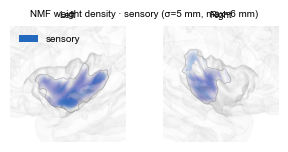

Wrote /hpc/group/coganlab/nanlinshi/insula-functional/img/nmf/nmf_weight_density_sensory.svg


libEGL warning: pci id for fd 100: 10de:26b2, driver (null)

pci id for fd 102: 10de:26b2, driver (null)
kmsro: driver missing
libEGL warning: egl: failed to create dri2 screen
libEGL warning: pci id for fd 100: 10de:26b2, driver (null)

pci id for fd 102: 10de:26b2, driver (null)
kmsro: driver missing
libEGL warning: egl: failed to create dri2 screen
libEGL warning: failed to open /dev/dri/card8: Permission denied

2026-09-27 12:40:00.346 (3742.889s) [    7F9EDB786740] vtkEGLRenderWindow.cxx:353   WARN| vtkEGLRenderWindow (0xca7b2d0): EGL device index: 0 could not be initialized. Trying other devices...
libEGL warning: pci id for fd 100: 10de:26b2, driver (null)

pci id for fd 102: 10de:26b2, driver (null)
kmsro: driver missing
libEGL warning: egl: failed to create dri2 screen
libEGL warning: pci id for fd 100: 10de:26b2, driver (null)

pci id for fd 102: 10de:26b2, driver (null)
kmsro: driver missing
libEGL warning: egl: failed to create dri2 screen
libEGL warning: failed to open /de

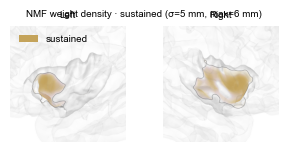

Wrote /hpc/group/coganlab/nanlinshi/insula-functional/img/nmf/nmf_weight_density_sustain.svg


libEGL warning: pci id for fd 100: 10de:26b2, driver (null)

pci id for fd 102: 10de:26b2, driver (null)
kmsro: driver missing
libEGL warning: egl: failed to create dri2 screen
libEGL warning: pci id for fd 100: 10de:26b2, driver (null)

pci id for fd 102: 10de:26b2, driver (null)
kmsro: driver missing
libEGL warning: egl: failed to create dri2 screen
libEGL warning: failed to open /dev/dri/card8: Permission denied

2026-09-27 12:40:03.408 (3745.951s) [    7F9EDB786740] vtkEGLRenderWindow.cxx:353   WARN| vtkEGLRenderWindow (0xc1cd2d0): EGL device index: 0 could not be initialized. Trying other devices...
libEGL warning: pci id for fd 100: 10de:26b2, driver (null)

pci id for fd 102: 10de:26b2, driver (null)
kmsro: driver missing
libEGL warning: egl: failed to create dri2 screen
libEGL warning: pci id for fd 100: 10de:26b2, driver (null)

pci id for fd 102: 10de:26b2, driver (null)
kmsro: driver missing
libEGL warning: egl: failed to create dri2 screen
libEGL warning: failed to open /de

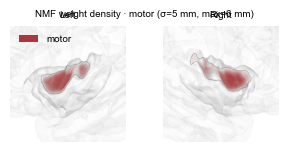

Wrote /hpc/group/coganlab/nanlinshi/insula-functional/img/nmf/nmf_weight_density_motor.svg


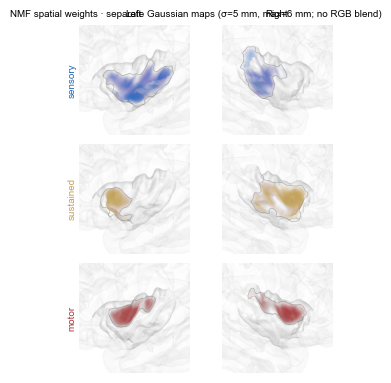

Wrote /hpc/group/coganlab/nanlinshi/insula-functional/img/nmf/nmf_weight_density_all.svg


In [40]:
cord = frame[["x", "y", "z"]].to_numpy(float)
mask_lh = cord[:, 0] < 0
mask_rh = cord[:, 0] > 0

component_images = {}

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for name in COMPONENTS:
        w = frame[LOADING_COLS[name]].to_numpy(float)
        color = FUNCTION_COLORS[name]
        lh_img = render_component_hemi("lh", cord[mask_lh], w[mask_lh], color)
        rh_img = render_component_hemi("rh", cord[mask_rh], w[mask_rh], color)
        component_images[name] = (lh_img, rh_img)

        fig, axes = plt.subplots(1, 2, figsize=(8 * cm, 3.5 * cm))
        axes[0].imshow(lh_img)
        axes[0].axis("off")
        axes[0].set_title("Left", fontsize=fontsize)
        axes[1].imshow(rh_img)
        axes[1].axis("off")
        axes[1].set_title("Right", fontsize=fontsize)
        axes[0].legend(
            handles=[Patch(facecolor=color, label=CLUSTER_LABELS.get(name, name))],
            loc="upper left",
            fontsize=fontsize,
            frameon=False,
        )
        fig.suptitle(
            f"NMF weight density · {CLUSTER_LABELS.get(name, name)} "
            f"(σ={DENSITY_BANDWIDTH:g} mm, max={DENSITY_MAX_DISTANCE:g} mm)",
            fontsize=fontsize,
        )
        fig.subplots_adjust(wspace=0.02, left=0.02, right=0.98, top=0.86, bottom=0.02)
        out = save_svg(fig, IMG_DIR / f"nmf_weight_density_{name}.svg")
        plt.show()
        print("Wrote", out)

# Combined three-row panel
fig, axes = plt.subplots(
    len(COMPONENTS), 2, figsize=(8 * cm, 3.2 * cm * len(COMPONENTS))
)
for row, name in enumerate(COMPONENTS):
    lh_img, rh_img = component_images[name]
    axes[row, 0].imshow(lh_img)
    axes[row, 0].axis("off")
    axes[row, 1].imshow(rh_img)
    axes[row, 1].axis("off")
    if row == 0:
        axes[row, 0].set_title("Left", fontsize=fontsize)
        axes[row, 1].set_title("Right", fontsize=fontsize)
    axes[row, 0].text(
        -0.02,
        0.5,
        CLUSTER_LABELS.get(name, name),
        transform=axes[row, 0].transAxes,
        va="center",
        ha="right",
        fontsize=fontsize,
        color=FUNCTION_COLORS[name],
        rotation=90,
    )

fig.suptitle(
    f"NMF spatial weights · separate Gaussian maps "
    f"(σ={DENSITY_BANDWIDTH:g} mm, max={DENSITY_MAX_DISTANCE:g} mm; no RGB blend)",
    fontsize=fontsize,
)
fig.subplots_adjust(wspace=0.02, hspace=0.08, left=0.08, right=0.98, top=0.94, bottom=0.02)
out_all = save_svg(fig, IMG_DIR / "nmf_weight_density_all.svg")
plt.show()
print("Wrote", out_all)
